In [2]:
pip install folium


  Using cached folium-0.20.0-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached branca-0.8.2-py3-none-any.whl.metadata (1.7 kB)
  Using cached xyzservices-2026.9.1-py3-none-any.whl.metadata (4.1 kB)
Using cached folium-0.20.0-py2.py3-none-any.whl (113 kB)
Using cached branca-0.8.2-py3-none-any.whl (26 kB)
Using cached xyzservices-2026.9.1-py3-none-any.whl (98 kB)

   -------------------------- ------------- 2/3 [folium]
   -------------------------- ------------- 2/3 [folium]
   ---------------------------------------- 3/3 [folium]

Note: you may need to restart the kernel to use updated packages.


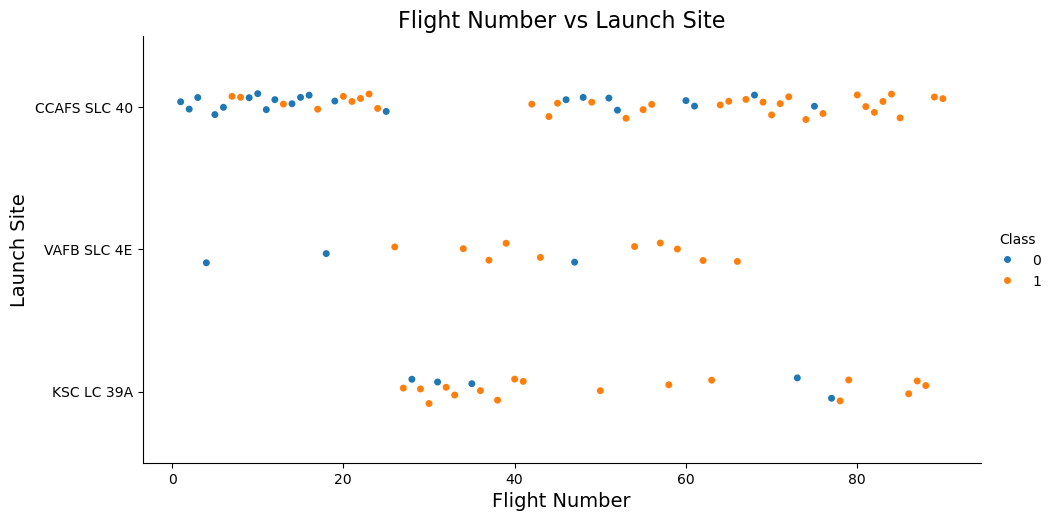

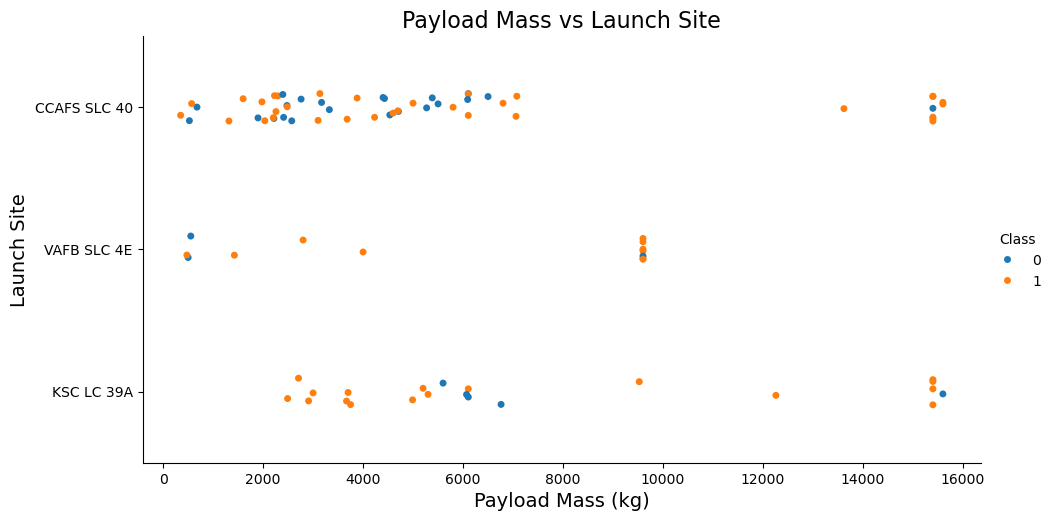

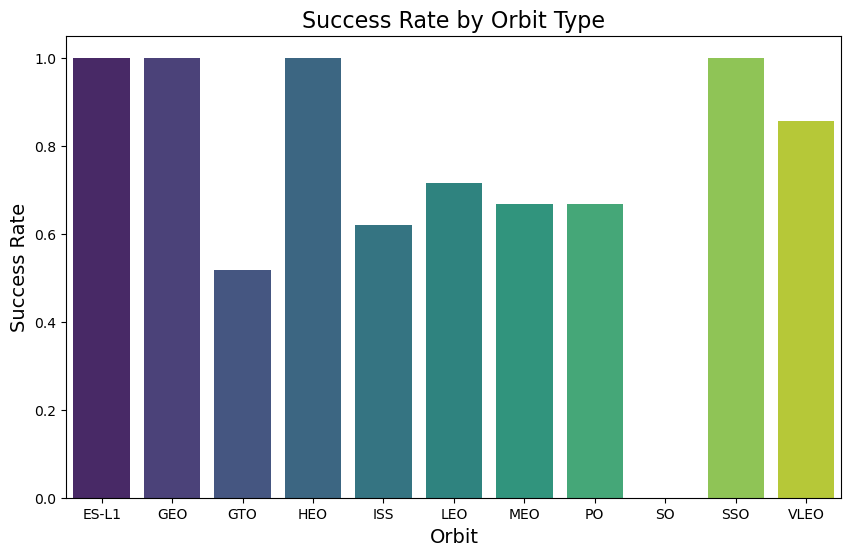

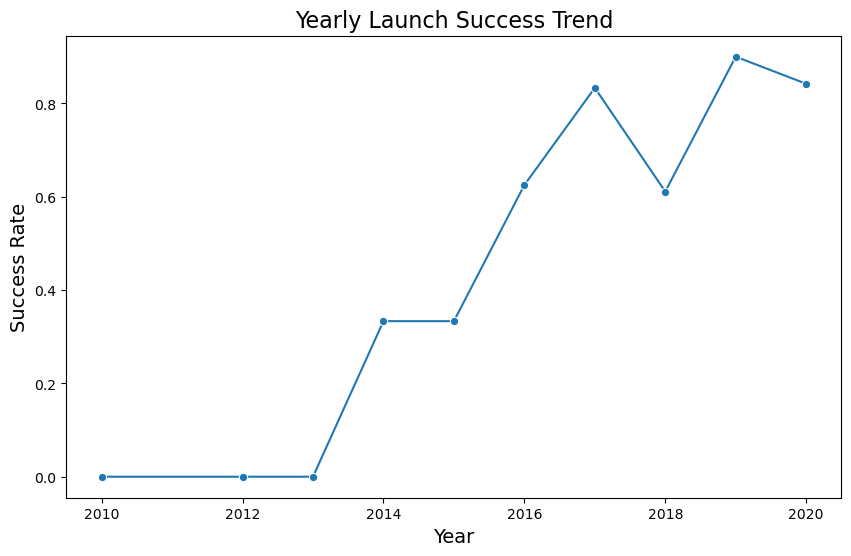

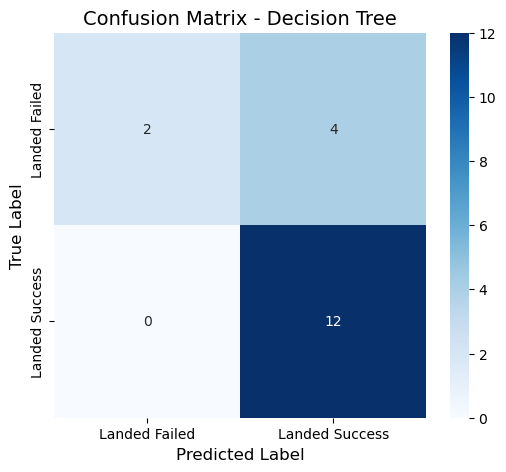

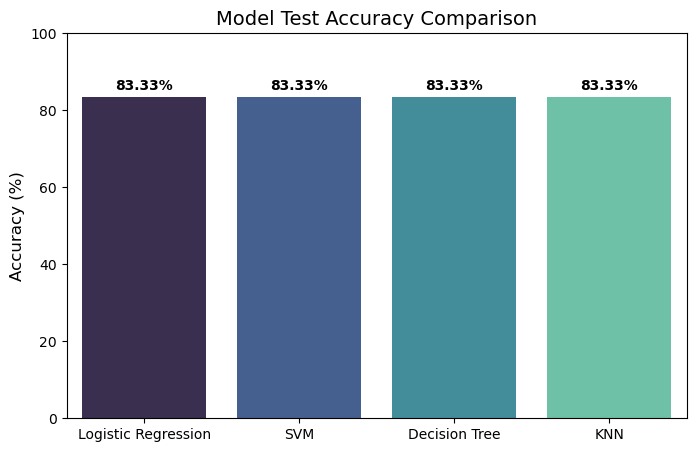

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster
from math import sin, cos, sqrt, atan2, radians
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from IPython.display import display

df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")
df_geo = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/spacex_launch_geo.csv")
X = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv")

sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect=2)
plt.xlabel("Flight Number", fontsize=14)
plt.ylabel("Launch Site", fontsize=14)
plt.title("Flight Number vs Launch Site", fontsize=16)
plt.savefig("flight_vs_launchsite.png", bbox_inches='tight')
plt.show()

sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect=2)
plt.xlabel("Payload Mass (kg)", fontsize=14)
plt.ylabel("Launch Site", fontsize=14)
plt.title("Payload Mass vs Launch Site", fontsize=16)
plt.savefig("payload_vs_launchsite.png", bbox_inches='tight')
plt.show()

orbit_success = df.groupby('Orbit')['Class'].mean().reset_index()
plt.figure(figsize=(10, 6))
sns.barplot(x="Orbit", y="Class", data=orbit_success, hue="Orbit", palette="viridis", legend=False)
plt.xlabel("Orbit", fontsize=14)
plt.ylabel("Success Rate", fontsize=14)
plt.title("Success Rate by Orbit Type", fontsize=16)
plt.savefig("orbit_success_rate.png", bbox_inches='tight')
plt.show()

df['Year'] = pd.to_datetime(df['Date']).dt.year
yearly_success = df.groupby('Year')['Class'].mean().reset_index()
plt.figure(figsize=(10, 6))
sns.lineplot(x="Year", y="Class", data=yearly_success, marker='o')
plt.xlabel("Year", fontsize=14)
plt.ylabel("Success Rate", fontsize=14)
plt.title("Yearly Launch Success Trend", fontsize=16)
plt.savefig("yearly_success_trend.png", bbox_inches='tight')
plt.show()

site_map = folium.Map(location=[28.562302, -80.577356], zoom_start=5)
marker_cluster = MarkerCluster().add_to(site_map)

for idx, record in df_geo.iterrows():
    icon_color = 'green' if record['class'] == 1 else 'red'
    folium.Marker(
        location=[record['Lat'], record['Long']],
        icon=folium.Icon(color='white', icon_color=icon_color),
        popup=f"Site: {record['Launch Site']} | Outcome: {'Success' if record['class'] == 1 else 'Failure'}"
    ).add_to(marker_cluster)

def calculate_distance(lat1, lon1, lat2, lon2):
    R = 6373.0
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))
    return R * c

launch_lat, launch_lon = 28.563197, -80.576820
coast_lat, coast_lon = 28.56367, -80.56778
distance_coast = calculate_distance(launch_lat, launch_lon, coast_lat, coast_lon)

folium.Marker(
    [coast_lat, coast_lon],
    icon=folium.DivIcon(html=f'<div style="font-size: 12; color:#d35400;"><b>{distance_coast:.2f} KM</b></div>')
).add_to(site_map)

folium.PolyLine(
    locations=[[launch_lat, launch_lon], [coast_lat, coast_lon]],
    weight=2,
    color='blue'
).add_to(site_map)

site_map.save("spacex_launch_map.html")
display(site_map)

Y = df['Class'].to_numpy()
transform = StandardScaler()
X_scaled = transform.fit_transform(X)

X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, Y, test_size=0.2, random_state=2)

tree_params = {
    'criterion': ['gini', 'entropy'],
    'splitter': ['best', 'random'],
    'max_depth': [2*n for n in range(1, 10)],
    'min_samples_split': [2, 5, 10]
}
tree_cv = GridSearchCV(DecisionTreeClassifier(), tree_params, cv=10)
tree_cv.fit(X_train, Y_train)

yhat = tree_cv.predict(X_test)
cm = confusion_matrix(Y_test, yhat)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Landed Failed', 'Landed Success'], yticklabels=['Landed Failed', 'Landed Success'])
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("Confusion Matrix - Decision Tree", fontsize=14)
plt.savefig("confusion_matrix.png", bbox_inches='tight')
plt.show()

models = ['Logistic Regression', 'SVM', 'Decision Tree', 'KNN']
test_accuracies = [83.33, 83.33, 83.33, 83.33]

plt.figure(figsize=(8, 5))
sns.barplot(x=models, y=test_accuracies, hue=models, palette='mako', legend=False)
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.title("Model Test Accuracy Comparison", fontsize=14)
for i, v in enumerate(test_accuracies):
    plt.text(i, v + 2, f"{v}%", ha='center', fontweight='bold')
plt.savefig("model_accuracy_comparison.png", bbox_inches='tight')
plt.show()